In [24]:
from IPython.core.display import HTML
HTML("""
<style>
.consignes{
  font-weight: bold;
  color: #3256a8;
  background-color: #edebdf
}
</style>
""")



# <div class=consignes>Deep Learning and signal processing Lab 1 </div>
<div class=consignes> The objective of this lab is to get familiar with the signal modelling and analysis tools presented in the first lecture and to introduce the <it>detection</it> problem that will be discussed in lecture number 3 </div>
<div class=consignes>Submission deadline: 14 October 2026, 13:59, by email to deepetsignal.mva@gmail.com <br> Estimated effort: 2 to 3 hours maximum</div>

<div class=consignes> List the names of the students (2 at most) who took part in this notebook in the following cell (first name, last name).<br/>
At submission time, the notebook must be named name1_name2_dlts_tp1.ipynb </div>



*   Pol Tibau Rubau
*   Pablo Borrego Ramos



<div class=consignes>If you install additional packages, please list them in the following cell with the syntax

```
!pip install \< package_name \>
```

</div>

In [2]:
import numpy as np
import matplotlib.pylab as plt
import scipy
import IPython.display as ipd

## <div class=consignes>Part 1: Audio </div>

### <div class=consignes>Visualization</div>

 <div class=consignes>Record a wav file of a few seconds of your voice.
  <br>
 Import it with scipy.io.wavfile.read and listen to it in the notebook with IPython.display.Audio
</div>

In [3]:
#@title Audio loading (base64-encoded) { display-mode: "form" }
AUDIO_B64 = "..."

<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color: #2e7d32;">Note on the audio</b></p>

<p>So that the notebook can be run by anyone without depending on an external file (which disappears every time the Colab session restarts), the <code style="background: transparent; color: inherit; padding: 0;">.wav</code> file was encoded in base64 and embedded directly in the following cell. It is decoded in memory and then read with <code style="background: transparent; color: inherit; padding: 0;">scipy.io.wavfile.read</code>, as requested in the assignment.</p>
</div>

In [4]:
import base64, io
import scipy.io.wavfile

samplerate, data = scipy.io.wavfile.read(io.BytesIO(base64.b64decode(AUDIO_B64)))
print(data.shape)
print(samplerate)
ipd.Audio(data, rate=samplerate)

(202069,)
16000


<div class=consignes>Visualize the time waveform of this audio signal. <br>
Estimate and display its Power Spectral Density. <br>
Give an interpretation of what you observe.
    </div>

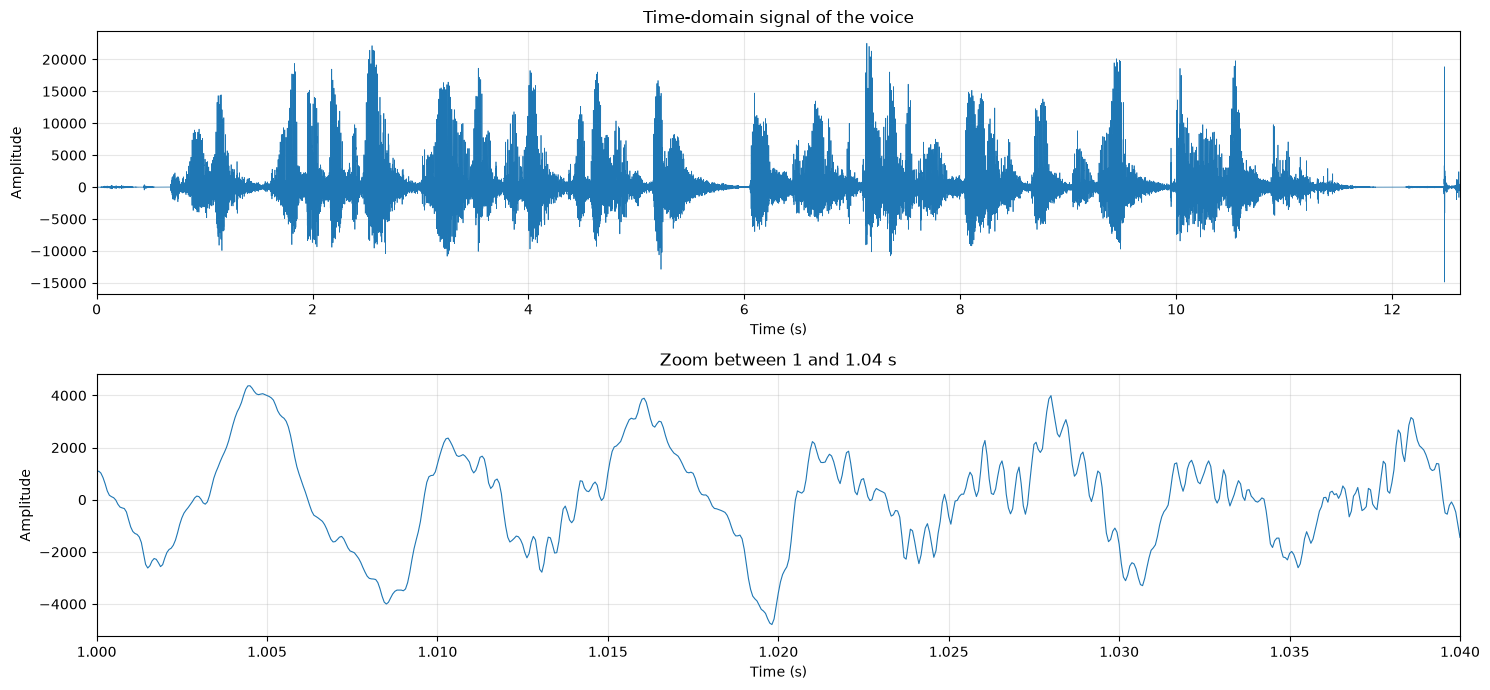

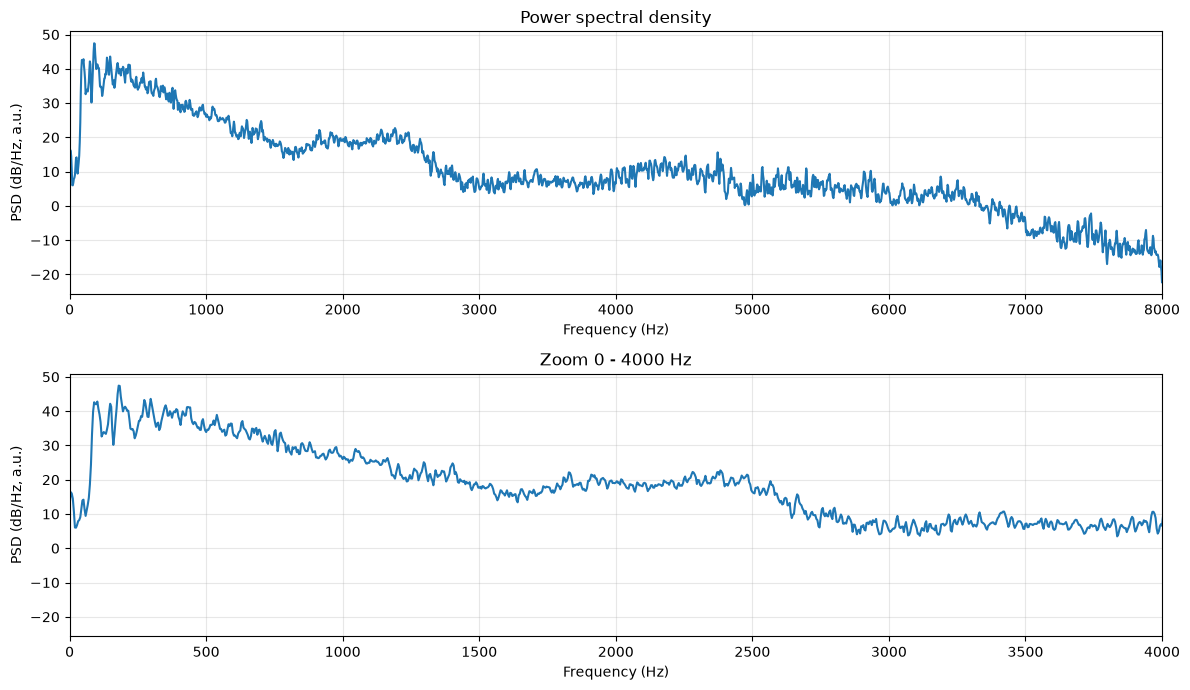

In [5]:
from scipy.signal import welch

#we build a vector to define the "time"
t = np.arange(len(data))/samplerate

#then we plot the time series
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7))

# Full signal
ax1.plot(t, data, linewidth=0.5)
ax1.set_xlim(t[0], t[-1])
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Amplitude')
ax1.set_title('Time-domain signal of the voice')
ax1.grid(alpha=0.3)

# Zoom on 40 ms
m = (t >= 1) & (t <= 1.04)
ax2.plot(t[m], data[m], linewidth=0.8)
ax2.set_xlim(1, 1.04)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Amplitude')
ax2.set_title('Zoom between 1 and 1.04 s')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

f, Pxx = welch(data, fs=samplerate, nperseg=4096)
Pxx_db = 10*np.log10(Pxx)    # conversion to dB (relative scale, arbitrary units)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7))

# PSD over the whole band
ax1.plot(f, Pxx_db)
ax1.set_xlim(0, samplerate/2)          # up to Nyquist
ax1.set_xlabel('Frequency (Hz)')
ax1.set_ylabel('PSD (dB/Hz, a.u.)')
ax1.set_title('Power spectral density')
ax1.grid(alpha=0.3)

# Zoom on 0-4000 Hz
ax2.plot(f, Pxx_db)
ax2.set_xlim(0, 4000)
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('PSD (dB/Hz, a.u.)')
ax2.set_title('Zoom 0 - 4000 Hz')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p><b>Time-domain signal.</b> The amplitude alternates between speech segments and pauses where only the background noise remains. In the 40 ms zoom, two time scales can be seen: a pattern that repeats every ≈ 11 ms (f<sub>0</sub> ≈ 90 Hz, a low voice) and, within each period, much faster oscillations that are damped. This is what the speech production model of the slides describes: the vocal cords generate a pulse train of frequency f<sub>0</sub> (the <i>source</i>; for unvoiced sounds it is noise), and the vocal tract, which acts as a <i>filter</i>, resonates after each pulse.</p>

<p><b>PSD estimation.</b> The PSD is defined with an expectation that we cannot compute from a single recording, so we estimate it. The problem is that the periodogram |FT(x)|²/T has a very large variance, which does not decrease with the duration of the signal, so we use Welch's method to reduce it. It averages the periodograms of K segments (variance ∝ 1/K) and, since K·nperseg ≈ N, the price is the resolution: Δf = f<sub>s</sub>/nperseg. We choose nperseg = 4096 (Δf ≈ 3.9 Hz), enough to resolve harmonics spaced by ≈ 90 Hz with margin, while the default 50 % overlap still leaves 97 segments to average, which strongly reduces the variance.</p>

<p><b>Interpretation of the PSD.</b> In frequency, the source-filter model predicts that the pulse train gives peaks at f<sub>0</sub>, 2f<sub>0</sub>, 3f<sub>0</sub>... (the harmonics), and that the filter determines their height, that is, the envelope of the spectrum.</p>

<p>The envelope is clearly visible in the PSD: the power is concentrated at low frequencies and decreases with frequency, with most of it below ~3 kHz, as indicated in the course. What lies above comes mainly from unvoiced consonants, whose source is noise and which therefore have no harmonics.</p>

<p>As for the harmonics, they do not form a regular series: there are only a few peaks between 100 and 300 Hz, which are not multiples of a single f<sub>0</sub>. The most likely cause is that the pitch varies with the intonation along the sentence, and Welch averages the whole recording: the harmonics of segments with different f<sub>0</sub> fall at different places and get mixed, all the more so the higher the harmonic (a variation Δf<sub>0</sub> becomes kΔf<sub>0</sub> for the k-th harmonic). To see them, we need to analyse short segments where f<sub>0</sub> is almost constant, which is what the spectrogram below does.</p>
</div>

<div class=consignes> Compute and display the spectrogram of the signal. <br>
Justify the choice of settings you made. <br>
Select a relevant portion of the spectrogram to visually estimate the pitch of your voice.
    </div>

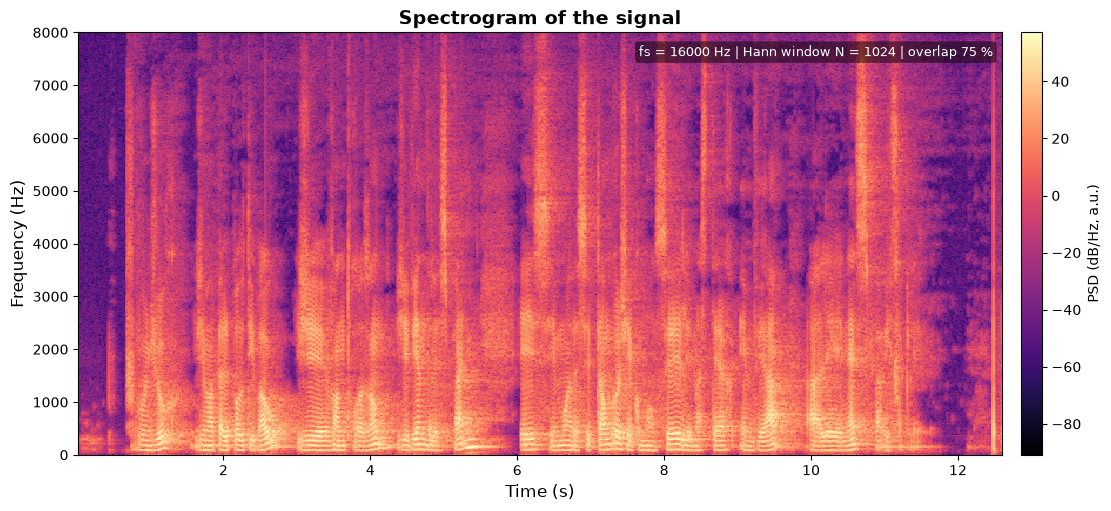

In [6]:
from scipy.signal import spectrogram
f, tt, S = spectrogram(data, fs=samplerate, window='hann', nperseg=1024, noverlap=768)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
pl = ax.pcolormesh(tt, f, 10 * np.log10(S), shading='auto', cmap='magma')
ax.set_title('Spectrogram of the signal', fontsize=14, fontweight='bold')
ax.set_xlabel('Time (s)', fontsize=12)
ax.set_ylabel('Frequency (Hz)', fontsize=12)
ax.set_ylim(0, samplerate / 2)
ax.tick_params(labelsize=10)

cbar = fig.colorbar(pl, ax=ax, pad=0.02)
cbar.set_label('PSD (dB/Hz, a.u.)')

ax.text(0.99, 0.97,
        f'fs = {samplerate} Hz | Hann window N = 1024 | overlap 75 %',
        transform=ax.transAxes, ha='right', va='top', fontsize=9, color='white',
        bbox=dict(boxstyle='round,pad=0.3', fc='black', alpha=0.5, ec='none'))

plt.show()

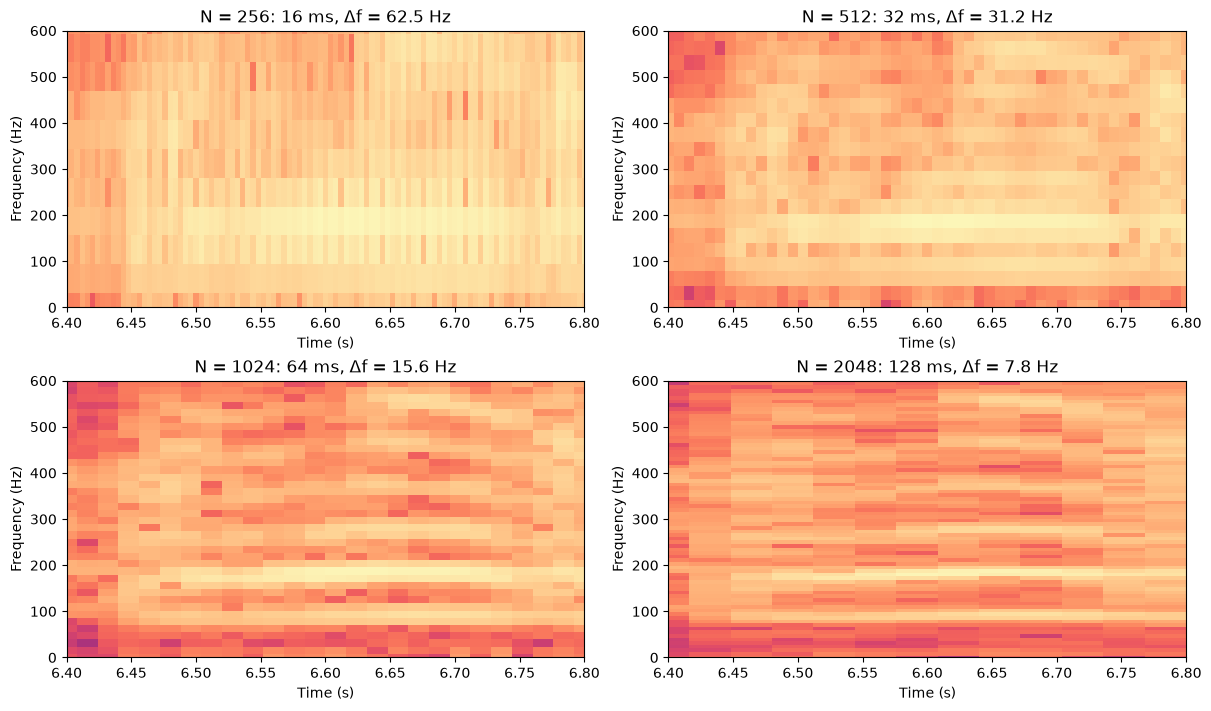

In [7]:
# Zoom on a voiced portion to read the pitch
fig, axs = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)

for ax, N in zip(axs.flat, [256, 512, 1024, 2048]):
    f_, t_, S_ = spectrogram(data, fs=samplerate, window='hann',
                             nperseg=N, noverlap=3*N//4)
    ax.pcolormesh(t_, f_, 10*np.log10(S_ + 1e-14), shading='auto', cmap='magma')
    ax.set_xlim(6.4, 6.8); ax.set_ylim(0, 600)
    ax.set_title(f'N = {N}: {1000*N/samplerate:.0f} ms, Δf = {samplerate/N:.1f} Hz')
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Frequency (Hz)')
plt.show()

<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p><b>Chosen parameters.</b> In the first plot, we use <code style="background: transparent; color: inherit; padding: 0;">nperseg=1024</code> and <code style="background: transparent; color: inherit; padding: 0;">noverlap=768</code>, with a Hann window. Since our audio has 16000 samples per second, each segment lasts 1024/16000 = 64 ms, and a Fourier transform is computed for each of them (STFT). This gives 513 frequencies between 0 and 8000 Hz (the Nyquist frequency, f<sub>s</sub>/2), that is, one pixel every 8000/512 ≈ 15.6 Hz in each column of the spectrogram.</p>

<p>The choice of these values comes from the search for a correct resolution both in frequency and in time, two things that cannot be improved at the same time (uncertainty principle, Δf·Δt ≥ constant). In particular, to separate two components δf apart, we must observe them for a time T such that T·δf is at least a few units. Here we want to separate the harmonics of our voice, spaced by f<sub>0</sub> ≈ 90 Hz: with 64 ms segments, T·f<sub>0</sub> ≈ 5.8. If, on the contrary, we had very short segments, of about 10 ms, each pixel would correspond to an increment of about 100 Hz and, with the broadening added by the Hann window, the harmonics of a low voice would be blurred.</p>

<p>Second, everything that happens within a segment is compressed into a single column, which can blur sudden changes, such as a rise in pitch or a consonant. According to the slides, the voice is only stationary over about 30 ms, so 64 ms is longer than ideal. However, a 32 ms segment would only contain ~2.9 periods of our low voice (T·f<sub>0</sub> ≈ 2.9), which is not enough to separate its harmonics clearly. Since our goal is to read the pitch, we prioritise frequency resolution and accept slightly violating stationarity (for a higher voice, ~30 ms would be enough). We studied this in the second figure, which compares N = 256, 512, 1024 and 2048 over the same segment. With 256 the harmonics merge, with 512 they appear as broad bands, while with 2048 little is gained in frequency and detail in time is lost. Keeping N = 1024 is therefore a reasonable compromise.</p>

<p><b>Window and overlap.</b> The Hann window progressively attenuates the edges of each segment, which limits the spectral leakage that an abrupt cut of the signal would produce, so that the harmonics appear cleaner. We use a high overlap (<code style="background: transparent; color: inherit; padding: 0;">noverlap=768</code>, i.e. 75 %), which, although it does not improve the resolution, avoids losing the information at the edges, which the window attenuates, and makes the spectrogram more continuous in time.</p>

<p><b>Pitch estimation.</b> In the zoom between 6.4 and 6.8 s, we can observe that the fundamental frequency lies just below 100 Hz, at around 90-95 Hz, which matches the period of about 11 ms observed in the time-domain zoom.</p>
</div>

###<div class=consignes>Pitch computation</div>

<div class=consignes>Propose a simple method to automatically estimate the Pitch of your voice (this method must not rely on external implementations).

Use this method to estimate the variations of the Pitch along the signal, estimate the pitch every 20 ms and present your results visually.

Do not use a "ready-made" method that you could find, for example, in the librosa library.

Comment on your results.
    </div>

In [ ]:
def estimate_pitch(frame, fs, energy_min, fmin=60, fmax=400, r_min=0.5, tol=0.9):
    x = frame - np.mean(frame)
    energy = np.sum(x**2)
    #if the energy is under the minimum, we assume its pitch is NaN and will not be considered in the np.nanmedian
    if energy < energy_min:
        return np.nan

    #normalized autocorrelation (only for the lags of a plausible voice pitch). Each lag k is normalized by the energy
    #of the two parts that actually overlap (x[:-k] and x[k:]), not by the energy of the whole frame: otherwise r(k)
    #could not exceed (L-k)/L, which penalises long lags, i.e. low pitches (r <= 0.58 at 60 Hz with L = 640)
    k_min, k_max = int(fs/fmax), int(fs/fmin)
    lags = np.arange(k_min, k_max + 1)  #k is the lag of the shifted copy
    r = np.array([np.sum(x[:-k] * x[k:]) / np.sqrt(np.sum(x[:-k]**2) * np.sum(x[k:]**2)) for k in lags])
    if r.max() < r_min:
        return np.nan

    #without the bias, r is almost as high at 2T, 3T... as at the period T, so the global maximum can fall on a multiple
    #of the period (pitch divided by 2). We therefore keep the first local maximum (shortest lag) that reaches tol = 90 %
    #of the global maximum
    peaks = [i for i in range(1, len(r) - 1) if r[i] >= r[i-1] and r[i] >= r[i+1]] or [np.argmax(r)]
    i = next(i for i in peaks if r[i] >= tol * r.max())
    return fs / lags[i]


def median_filter_nan(p, width=5):
    """Replaces each voiced value by the median of the voiced values in a window of `width` frames (100 ms):
    an isolated jump (octave error) surrounded by correct values is removed, while unvoiced frames stay NaN."""
    out = p.copy()
    h = width // 2
    for j in np.where(~np.isnan(p))[0]:
        out[j] = np.nanmedian(p[max(0, j - h):j + h + 1])
    return out


#we cut the signal into 40 ms frames, one every 20 ms
L = int(0.040 * samplerate)
hop = int(0.020 * samplerate)
x = data.astype(float)
starts = np.arange(0, len(x) - L + 1, hop)
frames = np.array([x[i:i+L] for i in starts])
times = (starts + L/2) / samplerate

#Silence threshold: a frame is considered silence if its energy is below 1 % of the energy of the most energetic frame
energy_min = 0.01 * np.max(np.sum(frames**2, axis=1))
pitch_raw = np.array([estimate_pitch(fr, samplerate, energy_min) for fr in frames])
pitch = median_filter_nan(pitch_raw)
#check: same estimation with the search restricted to the typical male range (70-250 Hz)
pitch_70_250 = median_filter_nan(np.array([estimate_pitch(fr, samplerate, energy_min, fmin=70, fmax=250) for fr in frames]))

print(f'Voiced frames: {np.sum(~np.isnan(pitch))} / {len(pitch)}')
print(f'Median pitch: {np.nanmedian(pitch):.1f} Hz')
print(f'Values above 160 Hz: {np.sum(pitch_raw > 160)} before the median filter, {np.sum(pitch > 160)} after')
print(f'Same result with a 70-250 Hz search range: {np.array_equal(np.isnan(pitch), np.isnan(pitch_70_250))}, '
      f'max difference = {np.nanmax(np.abs(pitch - pitch_70_250)):.1f} Hz')


<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>Since the speaker is a man, the search could be restricted to 70–250 Hz, the typical male range given in the slides. Most estimates do not change, but a few frames do: those at ≈ 63–65 Hz (around 1.22 s and 4.16–4.22 s) become unvoiced, since their period is now out of the search range, and a few values at the edges of voiced segments change slightly (up to ≈ 30 Hz, e.g. around 1.2 s). Restricting the range would therefore not make the estimation more reliable, and it would require knowing who is speaking: we keep 60–400 Hz.</p>
</div>

In [ ]:
f_s, t_s, S_s = spectrogram(data, fs=samplerate, window='hann', nperseg=1024, noverlap=768)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax1.plot(times, pitch_raw, '.', color='lightgray', markersize=5, label='Before the median filter')
ax1.plot(times, pitch, '.', markersize=5, label='After the median filter') # Estimated pitch
ax1.axhline(np.nanmedian(pitch), color='gray', linestyle='--', linewidth=1, label=f'Median = {np.nanmedian(pitch):.0f} Hz')
#We use np.nanmedian instead of np.median to avoid finding a median = nan
ax1.set_ylabel('Pitch (Hz)')
ax1.set_title('Estimated pitch every 20 ms (normalized autocorrelation)')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.pcolormesh(t_s, f_s, 10*np.log10(S_s), shading='auto', cmap='magma') # Pitch over the spectrogram
ax2.plot(times, pitch, '.', color='cyan', markersize=4)
ax2.set_ylim(0, 400)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Frequency (Hz)')
ax2.set_title('Pitch over the spectrogram')

plt.tight_layout()
plt.show()


<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p><b>Method.</b> To estimate the pitch we used the autocorrelation, which measures the similarity of the signal with a copy of itself shifted by a lag k. Since the voiced segments are quasi-periodic, it has a maximum when k matches the period, from which we deduce the pitch as f<sub>0</sub> = f<sub>s</sub>/k. We only look for this maximum among the lags corresponding to 60 to 400 Hz: according to the slides, the pitch typically lies between 70 and 250 Hz for men and between 150 and 400 Hz for women, so this range covers any adult voice, with a small margin below 70 Hz.</p>

<p>Two details of the normalization matter. A first version divided the autocorrelation by the energy of the whole frame; but for a lag k only L−k samples overlap, so r(k) could not exceed (L−k)/L, which is only 0.58 at 60 Hz (L = 640). This penalised long lags, i.e. low voices (exactly our case), and favoured short ones, which produced octave errors. We therefore normalize each lag by the energy of the two parts that overlap, so that r(k) = 1 for a perfectly periodic signal whatever k. Without this bias, however, r is almost as high at twice the period as at the period itself, and the maximum sometimes jumped to 2T (pitch divided by two): we keep the first local maximum that reaches 90 % of the global one. Finally, a median filter over 5 frames (100 ms) replaces each value by the median of its voiced neighbours, which removes isolated jumps.</p>

<p>To obtain an estimate every 20 ms, we split the signal into 40 ms frames (<code>L</code>), each one starting 20 ms (<code>hop</code>) after the previous one. With a period of about 11 ms, a 20 ms frame would only contain about two periods and the autocorrelation would be unreliable, while 40 ms frames contain about 3.5 periods and remain close to the ~30 ms over which the voice is stationary.</p>

<p>Frames without pitch are stored as <code>np.nan</code>, so that they are not plotted and are ignored by <code>np.nanmedian</code>. We discard silences, defined as frames whose energy is below 1 % of that of the most energetic frame (<code>energy_min</code>), and non-periodic sounds such as consonants, whose normalized autocorrelation does not reach 0.5 (<code>r_min</code>).</p>

<p><b>Results.</b> Out of the 630 frames of the signal, 307 are considered voiced (218 with the biased normalization, which rejected many voiced frames), and their pitch has a median of about 91 Hz. 88 % of the values lie between 80 and 110 Hz, which matches what we had seen in the time-domain zoom and in the spectrogram. Moreover, we can observe that the pitch is not constant, but follows the intonation of the sentence. For example, it rises towards the end of some segments, such as around 1.1 s or 10.5 s, and between 5.3 s and 5.6 s there is a continuous segment at about 150 Hz, which corresponds to a rise in pitch. If we superimpose the pitch on the spectrogram, we see that the points follow the first horizontal band, the fundamental. This variation of the pitch also explains why the harmonics did not form a regular series in the PSD, which averages the whole recording.</p>

<p>The method has some limitations. A few values remain far from the usual pitch: isolated points at 1.62 s and 9.04 s (≈ 160–170 Hz), which the median filter cannot correct because they have no voiced neighbours, and the region around 4.2–4.4 s, where the estimate jumps from ≈ 64 Hz to 150–200 Hz. There the maximum of r is often barely above the threshold (0.50–0.55 in several frames): the signal is hardly periodic (transition between sounds), and a stricter periodicity threshold would rather classify these frames as unvoiced. Moreover, the energy (1 %), periodicity (0.5) and octave (90 %) thresholds were set empirically, and changing them changes which frames are considered voiced.</p>
</div>

## <div class=consignes>Part 2: Pulse detection </div>

<div class=consignes> A signal of duration 1 second, sampled at 1000 Hz, is made of a Gaussian white noise of unknown power and possibly a pulse at a frequency f0 between 100 and 200 Hz.
<br><br>
A series of 1000 signals is stored in the file signaux_impulsions.npz.
Open this file with numpy (see code below). The file contains an array signaux of size 10000 x 1000, each row of which contains a signal of length 1000. The file also contains an array labels of size 10000 whose row i is TRUE if signal i contains a pulse and 0 otherwise.

</div>

In [10]:
donnees = np.load('signaux_impulsions.npz')
signaux = donnees['data'] if 'data' in donnees.files else donnees['signaux']
labels = donnees['labels'].astype(bool)
fs = 1000 

<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Exploration of the data</b></p>

<p>Before designing a detector, we look at the main characteristics of the dataset: size and balance of the classes, noise level, and duration, frequency and position of the pulses.</p>
</div>

Signals: 10000, samples per signal: 1000 (1 s at 1000 Hz)
With a pulse: 5004 (50.0%), without a pulse: 4996
sigma of the signals without a pulse: 0.097 to 0.732 (noise power ratio max/min = 57), quartiles = 0.26, 0.40, 0.55
Largest envelope contrast of a signal without a pulse: 3.67

Clearly visible pulses: 2470, of which 603 (24%) are cut by an edge of the signal (61 at the beginning, 542 at the end)
Duration of the pulses not cut by an edge: 5 % / median / 95 % = 108 ms / 190 ms / 285 ms
Frequency of the pulses: 100 to 201 Hz, median 148 Hz


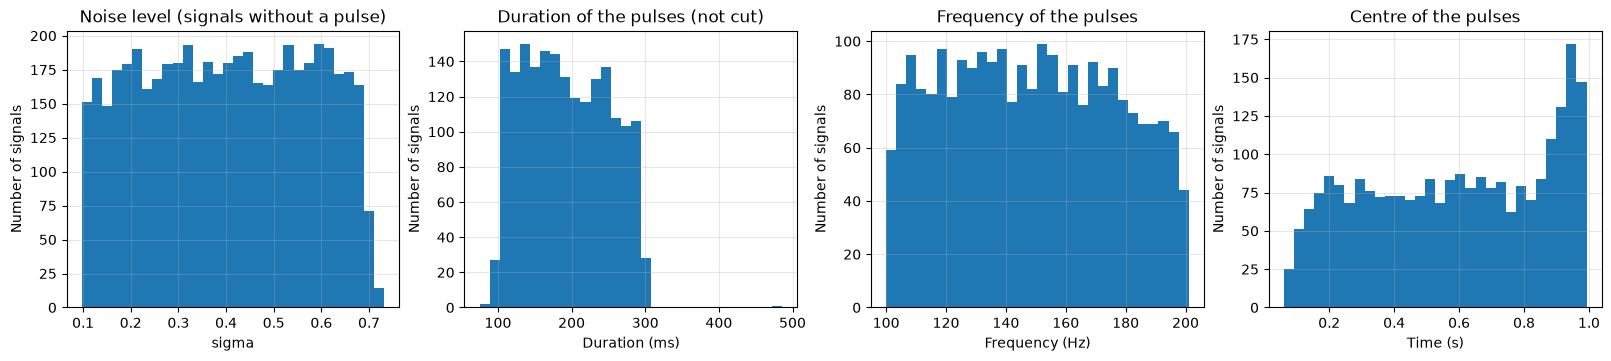

In [25]:
from scipy.signal import butter, sosfiltfilt, hilbert

print(f'Signals: {signaux.shape[0]}, samples per signal: {signaux.shape[1]} ({signaux.shape[1]/fs:.0f} s at {fs} Hz)')
print(f'With a pulse: {labels.sum()} ({labels.mean():.1%}), without a pulse: {(~labels).sum()}')

#noise level: for the signals without a pulse, the standard deviation of the signal is sigma
sigma_no_pulse = signaux[~labels].std(axis=1)
print(f'sigma of the signals without a pulse: {sigma_no_pulse.min():.3f} to {sigma_no_pulse.max():.3f} '
      f'(noise power ratio max/min = {(sigma_no_pulse.max() / sigma_no_pulse.min())**2:.0f}), '
      f'quartiles = {", ".join(f"{q:.2f}" for q in np.percentile(sigma_no_pulse, [25, 50, 75]))}')

#characteristics of the pulses: we keep the band 95-205 Hz (band-pass filter), compute the envelope with the Hilbert
#transform (smoothed over 15 ms) and measure where it exceeds half of its maximum. This is only reliable for clearly
#visible pulses, so we keep the signals whose envelope peak is more than 5 times its median value (no signal without a
#pulse reaches this contrast, see the printed value)
sos = butter(6, [95, 205], btype='band', fs=fs, output='sos')
env = np.abs(hilbert(sosfiltfilt(sos, signaux, axis=1), axis=1))
env = np.array([np.convolve(e, np.ones(15) / 15, mode='same') for e in env])
contrast = env.max(axis=1) / np.median(env, axis=1)
print(f'Largest envelope contrast of a signal without a pulse: {contrast[~labels].max():.2f}')

clear = np.where(labels & (contrast > 5))[0]
start, end, freq = [], [], []
f_fft = np.fft.rfftfreq(8192, 1/fs)
for i in clear:
    above = np.where(env[i] > env[i].max() / 2)[0]
    start.append(above[0]); end.append(above[-1])
    #frequency of the pulse: maximum of the spectrum (zero-padded FFT) of the segment where it is present
    spectrum = np.abs(np.fft.rfft(signaux[i, above[0]:above[-1] + 1], 8192))
    freq.append(f_fft[np.argmax(np.where((f_fft >= 90) & (f_fft <= 210), spectrum, 0))])
start, end, freq = np.array(start), np.array(end), np.array(freq)
duration = (end - start) / fs
#pulses that touch the beginning or the end of the signal are cut: their duration is not the real one
inside = (start > 20) & (end < signaux.shape[1] - 21)
print(f'\nClearly visible pulses: {len(clear)}, of which {np.sum(~inside)} ({np.mean(~inside):.0%}) are cut by an edge of the signal '
      f'({np.sum(start <= 20)} at the beginning, {np.sum(end >= signaux.shape[1] - 21)} at the end)')
print('Duration of the pulses not cut by an edge: 5 % / median / 95 % = '
      + ' / '.join(f'{1000*d:.0f} ms' for d in np.percentile(duration[inside], [5, 50, 95])))
print(f'Frequency of the pulses: {freq.min():.0f} to {freq.max():.0f} Hz, median {np.median(freq):.0f} Hz')

fig, axs = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
axs[0].hist(sigma_no_pulse, bins=30)
axs[0].set_xlabel('sigma'); axs[0].set_title('Noise level (signals without a pulse)')
axs[1].hist(1000 * duration[inside], bins=30)
axs[1].set_xlabel('Duration (ms)'); axs[1].set_title('Duration of the pulses (not cut)')
axs[2].hist(freq, bins=30)
axs[2].set_xlabel('Frequency (Hz)'); axs[2].set_title('Frequency of the pulses')
axs[3].hist((start + end) / 2 / fs, bins=30)
axs[3].set_xlabel('Time (s)'); axs[3].set_title('Centre of the pulses')
for ax in axs:
    ax.set_ylabel('Number of signals'); ax.grid(alpha=0.3)
plt.show()


<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>The 10000 signals are balanced (5004 with a pulse, 4996 without), so the accuracy is a meaningful criterion to choose a threshold. The noise level varies a lot: σ is spread roughly uniformly between 0.1 and 0.73, i.e. a factor of 57 in noise power, which already suggests that a detector based on the absolute energy will struggle.</p>

<p>The pulses have a frequency spread over the whole band 100-200 Hz and start at any time of the second. They are short: between ≈ 110 and ≈ 285 ms (5 % and 95 % percentiles), 190 ms in the median. Moreover, about a quarter of the clearly visible pulses are cut by an edge of the signal and are therefore even shorter: almost always by the end (542 of the 603 cut pulses), since a pulse that starts late in the second does not have time to finish. This is why the centres of the visible part of the pulses accumulate near 1 s. These durations will matter when choosing the window of the spectrogram in the second method. These measures only use the clearly visible pulses (envelope contrast above 5, never reached by pure noise), so they describe the shape of the pulses rather than their amplitude.</p>
</div>

## <div class=consignes> First method </div>

<div class=consignes> Propose a simple method to decide whether a signal contains a pulse or not, based on the computation of the signal energy. This method will involve a threshold:
</div>

```python
def contient_impulsion_energie(signal: np.ndarray, seuil: float) -> bool:
```

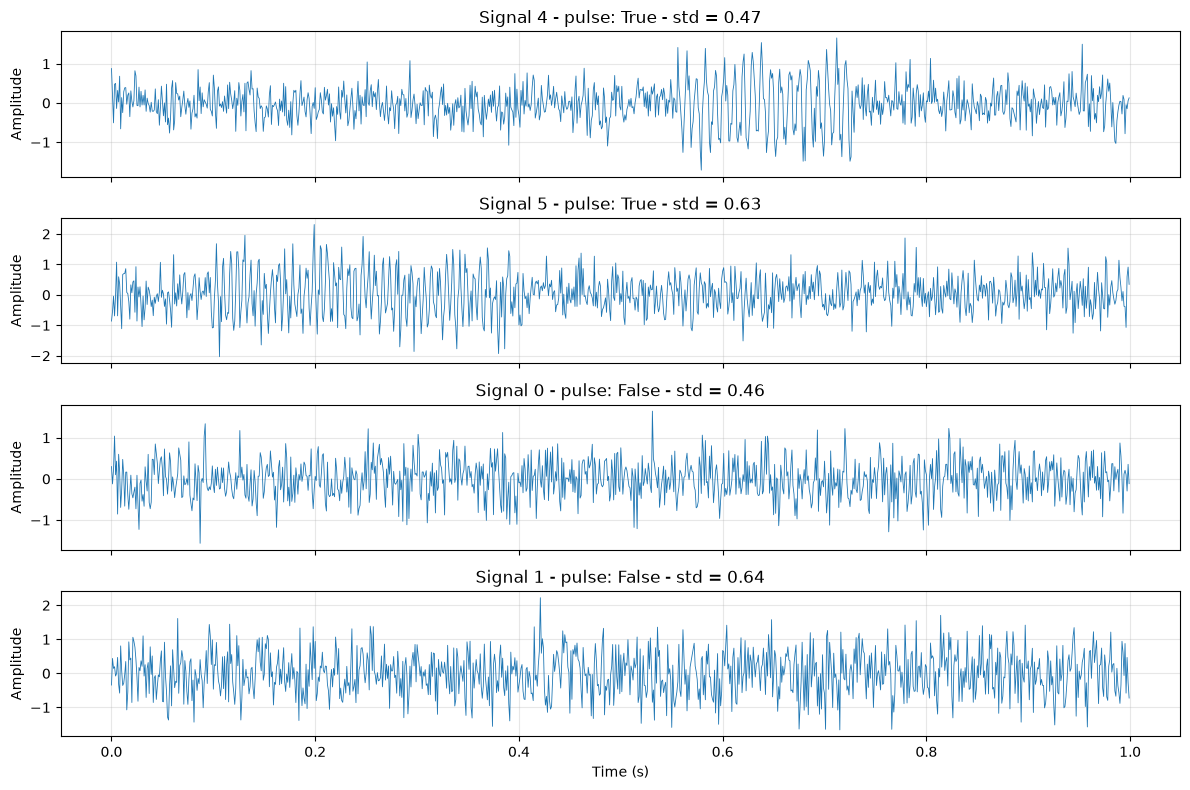

In [11]:
#before designing a detector we look at the data, to see what a pulse looks like and how strong the noise is
t_sig = np.arange(signaux.shape[1]) / fs  

#indices of the first two signals with a pulse and the first two without
idx = np.concatenate([np.where(labels)[0][:2], np.where(~labels)[0][:2]])

fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, i in zip(axs, idx):
    ax.plot(t_sig, signaux[i], linewidth=0.6)
    #we display the standard deviation of each signal, which gives an idea of its noise level
    ax.set_title(f'Signal {i} - pulse: {labels[i]} - std = {signaux[i].std():.2f}')
    ax.set_ylabel('Amplitude')
    ax.grid(alpha=0.3)
axs[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>In signals 4 and 5 the pulse is visible as a segment (around 0.53-0.75 s and 0.1-0.38 s) where the signal oscillates more strongly and more regularly, while signals 0 and 1 look the same during the whole second. However, the global energy (E &asymp; N&middot;std<sup>2</sup>) does not help to differentiate them: for example, signal 0 (no pulse, E &asymp; 213) has almost the same energy as signal 4 (pulse, E &asymp; 220), and signal 1 (no pulse, E &asymp; 405) almost twice as much. What reveals the pulse is the contrast between one part of the signal and the rest of it, which does not depend on the noise power.</p>
</div>

In [12]:
def contient_impulsion_energie(signal: np.ndarray, seuil: float) -> bool:
    """Returns True if the energy of the signal (sum of its squared samples) is above the threshold."""
    #without a pulse the energy is that of the noise alone (about N*sigma^2); a pulse adds its own energy on top
    #of it, so a high energy suggests that a pulse is present
    return bool(np.sum(signal**2) > seuil)

<div class=consignes>
Use your method with a fixed threshold on all the signals to predict whether they contain a pulse or not.
</div>

<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>As seen in the previous figure, this method is not expected to work well, since the energy also depends on the noise power, which changes from one signal to another, but it gives a baseline for the second method.</p>
</div>

In [ ]:
#energy of every signal: we square the samples and sum along each row (axis=1), since one row = one signal.
#This gives the same values as contient_impulsion_energie, but for the 10000 signals at once
energies = np.sum(signaux**2, axis=1)

#choice of the threshold: we try 1000 candidate values between the smallest energy and the 99th percentile
#and keep the one that maximises the fraction of correct decisions (accuracy). Maximising the accuracy is
#reasonable here because the two classes have the same size (~50 % each), so no class dominates the score
seuils = np.linspace(energies.min(), np.percentile(energies, 99), 1000)
accuracy = [np.mean((energies > s) == labels) for s in seuils]  #(energies > s) are the predictions for threshold s
seuil_energie = seuils[np.argmax(accuracy)]
print(f'Chosen threshold: {seuil_energie:.1f} (accuracy = {max(accuracy):.3f})')

#numbers quoted in the observations below: average energy added by a pulse, and largest energy reached by pure noise
print(f'Mean energy with a pulse - mean energy without: {energies[labels].mean() - energies[~labels].mean():.1f}')
print(f'Largest energy of a signal without a pulse: {energies[~labels].max():.1f}')

#predictions of the method with this fixed threshold, using the function defined above
pred_energie = np.array([contient_impulsion_energie(x, seuil_energie) for x in signaux])

#distribution of the energy for each class: if the two histograms were well separated, a threshold between
#them would classify almost every signal correctly; the overlap shows how many errors are unavoidable
bins = np.linspace(0, np.percentile(energies, 99.5), 100)  #same bins for both classes so they can be compared
plt.figure(figsize=(10, 4))
plt.hist(energies[~labels], bins=bins, alpha=0.5, label='No pulse')
plt.hist(energies[labels], bins=bins, alpha=0.5, label='Pulse')
plt.axvline(seuil_energie, color='k', linestyle='--', label=f'Threshold = {seuil_energie:.0f}')
plt.xlabel('Energy')
plt.ylabel('Number of signals')
plt.title('Energy of the signals with and without a pulse')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>Without a pulse E &asymp; N&sigma;<sup>2</sup>, so the blue histogram is the distribution of the noise power over the signals (&sigma; between about 0.1 and 0.73). The orange one has roughly the same shape, shifted to the right by the energy of the pulse (about 90 on average). This shift is small compared with the spread of the noise power, so the two distributions overlap almost completely: only below about 100 are there clearly more signals without a pulse. With balanced classes, the threshold that minimises the errors is where the two densities cross, hence the optimal threshold &asymp; 109. Above it, only 59 % of the detections are real pulses.</p>
</div>

<div class=consignes>
Compute: <br>
- TP = the number of signals you detect as containing a pulse that actually contain a pulse <br>
- FP = the number of signals you detect as containing a pulse that in fact do NOT contain a pulse <br>
- TN = the number of signals you detect as NOT containing a pulse that indeed do NOT contain a pulse<br>
- FN = the number of signals you detect as NOT containing a pulse but that in fact contain a pulse
</div>

In [14]:
#we compare the predictions with the ground truth (labels) using boolean masks:
#& = "and", ~ = "not", and np.sum counts the True values
TP = np.sum(pred_energie & labels)    #detected, and there is a pulse
FP = np.sum(pred_energie & ~labels)   #detected, but there is no pulse (false alarm)
TN = np.sum(~pred_energie & ~labels)  #not detected, and there is no pulse
FN = np.sum(~pred_energie & labels)   #not detected, but there is a pulse (missed pulse)
#every signal falls into exactly one of the four cases
assert TP + FP + TN + FN == len(labels)

print(f'TP = {TP}, FP = {FP}, TN = {TN}, FN = {FN}')
#fraction of the pulses that we find, and fraction of the pure-noise signals that wrongly raise an alarm
print(f'Signals with a pulse that are detected: {TP/(TP+FN):.1%}')
print(f'Signals without a pulse that raise a false alarm: {FP/(FP+TN):.1%}')

TP = 4513, FP = 3104, TN = 1892, FN = 491
Signals with a pulse that are detected: 90.2%
Signals without a pulse that raise a false alarm: 62.1%


<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p><b>Method.</b> Without a pulse, the signal is Gaussian white noise and its energy E = &sum; x[n]<sup>2</sup> has mean N&sigma;<sup>2</sup> with small fluctuations (E/&sigma;<sup>2</sup> ~ &chi;<sup>2</sup>(N), standard deviation &asymp; 4.5 % of the mean). A pulse adds its own energy on average, so we decide that there is a pulse if E &gt; threshold. We keep the threshold that maximises the accuracy over 1000 candidate values (the classes are balanced); since it is chosen and evaluated on the same signals, the evaluation could be optimistic, which we check at the end of the notebook.</p>

<p><b>Results.</b> The best fixed threshold (&asymp; 109) only gives 64 % of correct decisions: 90 % of the pulses are detected, but 62 % of the signals without a pulse raise a false alarm.</p>

<p><b>Interpretation.</b> With a known and fixed &sigma;, the energy would be an excellent detector. But the noise power varies by a factor of about 50 between signals, so the energy mixes the presence of a pulse with the noise level. A good detector should be invariant to the noise level, which is the idea of the second method.</p>
</div>

## <div class=consignes>Second method </div>

<div class=consignes>Propose a second method involving, for example, the spectrogram of the signal. This method will also involve a threshold
</div>

```python
def contient_impulsion_spectrogramme(signal: np.ndarray, seuil: float) -> bool:
```


<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>The energy summarises each signal by a single number, which mixes the pulse with the noise level. However, the pulse is a sinusoid between 100 and 200 Hz that only lasts a fraction of the second, whereas white noise spreads its power evenly over all times and frequencies (its PSD is flat). In the spectrogram, the pulse should therefore appear as a localised spot on a uniform background, as shown below for the same four signals.</p>
</div>

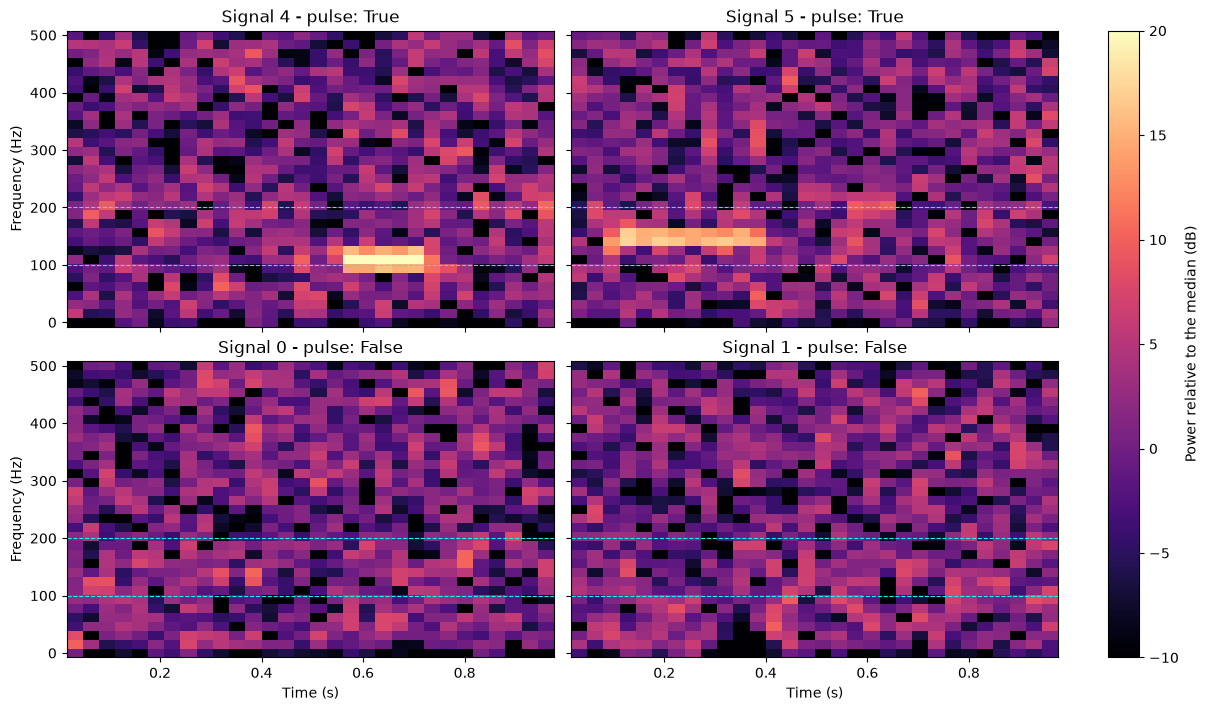

In [15]:
from scipy.signal import spectrogram

#parameters of the spectrogram: windows of 64 samples (64 ms, frequency resolution fs/64 = 15.6 Hz), with 50 % overlap.
#The window must be shorter than the pulse (which lasts a few hundred ms) so that it can fit entirely inside it,
#and long enough to separate the band 100-200 Hz from the rest of the spectrum
nperseg_sp = 64
noverlap_sp = 32

fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, i in zip(axs.flat, idx):
    f_sp, t_sp, S_sp = spectrogram(signaux[i], fs=fs, window='hann', nperseg=nperseg_sp, noverlap=noverlap_sp)
    #we divide by the median of the spectrogram, which estimates the noise level, so that the four signals are
    #displayed on the same scale whatever their noise power (0 dB = typical noise level)
    pl = ax.pcolormesh(t_sp, f_sp, 10*np.log10(S_sp / np.median(S_sp)), shading='auto', cmap='magma', vmin=-10, vmax=20)
    ax.axhline(100, color='cyan', linestyle='--', linewidth=0.8)  #band where the pulse can be
    ax.axhline(200, color='cyan', linestyle='--', linewidth=0.8)
    ax.set_title(f'Signal {i} - pulse: {labels[i]}')
for ax in axs[-1]:
    ax.set_xlabel('Time (s)')
for ax in axs[:, 0]:
    ax.set_ylabel('Frequency (Hz)')
fig.colorbar(pl, ax=axs, label='Power relative to the median (dB)')
plt.show()

<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>In signals 4 and 5 the pulse appears as a short horizontal segment of high power inside the band 100-200 Hz, at the same times as in the time domain, while elsewhere and in signals 0 and 1 the spectrogram is a uniform noise background. Since each spectrogram is divided by its median, this background looks the same in the four signals despite their different noise powers: what reveals the pulse is the contrast between the spot and the background.</p>
</div>

In [16]:
def rapport_spectrogramme(signal: np.ndarray) -> float:
    """Ratio between the most powerful pixel of the band 100-200 Hz and the median power of the spectrogram."""
    f_sp, t_sp, S_sp = spectrogram(signal, fs=fs, window='hann', nperseg=nperseg_sp, noverlap=noverlap_sp)
    #noise level: the median of all the pixels. Since the pulse only occupies a few pixels, it has almost no
    #influence on the median, which therefore estimates the power of the noise alone (unlike the mean)
    noise_level = np.median(S_sp)
    #power of the pulse: the most powerful pixel in the band where the pulse can be
    band = (f_sp >= 100) & (f_sp <= 200)
    peak = np.max(S_sp[band, :])
    #without a pulse, all the pixels are proportional to sigma^2, so the ratio does not depend on the noise power
    return peak / noise_level


def contient_impulsion_spectrogramme(signal: np.ndarray, seuil: float) -> bool:
    """Returns True if the spectrogram of the signal contains, in the band 100-200 Hz, a pixel whose power is
    more than `seuil` times the typical noise level of the spectrogram."""
    return bool(rapport_spectrogramme(signal) > seuil)

<div class=consignes> For this new method, compute the values of TP, FP, TN, FN for a given threshold </div>

Chosen threshold: 19.8 (accuracy = 0.982)
TP = 4833, FP = 5, TN = 4991, FN = 171
Signals with a pulse that are detected: 96.6%
Signals without a pulse that raise a false alarm: 0.1%


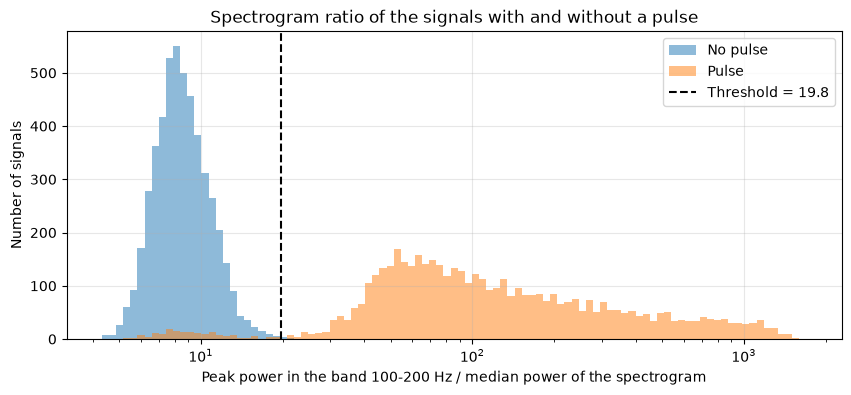

In [17]:
#ratio of every signal (same statistic as in contient_impulsion_spectrogramme, computed once for all the signals)
rapports = np.array([rapport_spectrogramme(x) for x in signaux])

#choice of the threshold: same procedure as for the first method, we keep the value that maximises the accuracy
seuils_sp = np.linspace(rapports.min(), np.percentile(rapports, 99), 1000)
accuracy_sp = [np.mean((rapports > s) == labels) for s in seuils_sp]
seuil_spectro = seuils_sp[np.argmax(accuracy_sp)]
print(f'Chosen threshold: {seuil_spectro:.1f} (accuracy = {max(accuracy_sp):.3f})')

pred_spectro = np.array([contient_impulsion_spectrogramme(x, seuil_spectro) for x in signaux])

#confusion counts, exactly as for the first method
TP_sp = np.sum(pred_spectro & labels)    #detected, and there is a pulse
FP_sp = np.sum(pred_spectro & ~labels)   #detected, but there is no pulse (false alarm)
TN_sp = np.sum(~pred_spectro & ~labels)  #not detected, and there is no pulse
FN_sp = np.sum(~pred_spectro & labels)   #not detected, but there is a pulse (missed pulse)
assert TP_sp + FP_sp + TN_sp + FN_sp == len(labels)

print(f'TP = {TP_sp}, FP = {FP_sp}, TN = {TN_sp}, FN = {FN_sp}')
print(f'Signals with a pulse that are detected: {TP_sp/(TP_sp+FN_sp):.1%}')
print(f'Signals without a pulse that raise a false alarm: {FP_sp/(FP_sp+TN_sp):.1%}')

#distribution of the ratio for each class (logarithmic scale, since the ratio covers several orders of magnitude)
bins_sp = np.logspace(np.log10(rapports.min()), np.log10(rapports.max()), 100)
plt.figure(figsize=(10, 4))
plt.hist(rapports[~labels], bins=bins_sp, alpha=0.5, label='No pulse')
plt.hist(rapports[labels], bins=bins_sp, alpha=0.5, label='Pulse')
plt.axvline(seuil_spectro, color='k', linestyle='--', label=f'Threshold = {seuil_spectro:.1f}')
plt.xscale('log')
plt.xlabel('Peak power in the band 100-200 Hz / median power of the spectrogram')
plt.ylabel('Number of signals')
plt.title('Spectrogram ratio of the signals with and without a pulse')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#analysis of the errors of the second method. We need, for every signal, an estimate of its noise level: we compute
#the spectrograms of all the signals at once (axis=-1: one spectrogram per row) and take the median of each of them,
#which is proportional to sigma^2
f_all, t_all, S_all = spectrogram(signaux, fs=fs, window='hann', nperseg=nperseg_sp, noverlap=noverlap_sp, axis=-1)
noise_level = np.median(S_all, axis=(1, 2))

#to convert the median of the spectrogram into a variance sigma^2, we use the signals without a pulse,
#for which sigma^2 is simply the variance of the signal
k = np.median(np.var(signaux[~labels], axis=1) / noise_level[~labels])
sigma2 = k * noise_level
N = signaux.shape[1]

#1) false alarms and detections as a function of the noise level: we sort the signals by sigma^2, split them into
#   5 groups of the same size (from the least to the most noisy) and compute the fraction of positive decisions
def by_noise_quintile(idx):
    return np.array_split(idx[np.argsort(sigma2[idx])], 5)
print('From the least noisy to the most noisy 20 % of the signals:')
print('   false alarms (no pulse): ' + '   '.join(f'{np.mean(pred_spectro[g]):5.1%}' for g in by_noise_quintile(np.where(~labels)[0])))
print('   detections (pulse):      ' + '   '.join(f'{np.mean(pred_spectro[g]):5.1%}' for g in by_noise_quintile(np.where(labels)[0])))

#2) signal-to-noise ratio of each pulse, as defined in the course: SNR = 10 log10(P_pulse / P_noise), both powers
#   taken over the whole second. The energy of the pulse alone is estimated as the energy of the signal minus that of
#   the noise, N*sigma^2. For very weak pulses this difference is dominated by the fluctuations of the noise energy
#   (std ~ sqrt(2N)*sigma^2, i.e. about -13 dB of N*sigma^2) and can even be negative: those SNRs are only indicative
energie_pulse = energies - N * sigma2
valid = labels & (energie_pulse > 0)
snr_db = np.full(len(labels), np.nan)
snr_db[valid] = 10 * np.log10(energie_pulse[valid] / (N * sigma2[valid]))
print(f'\nMedian SNR of the pulses: detected = {np.nanmedian(snr_db[labels & pred_spectro]):.1f} dB, '
      f'missed = {np.nanmedian(snr_db[labels & ~pred_spectro]):.1f} dB '
      f'({np.sum(labels & ~valid)} pulses with an estimated energy <= 0 are left out)')
print('   median SNR per noise quintile:   ' + '   '.join(f'{np.nanmedian(snr_db[g]):5.1f} dB' for g in by_noise_quintile(np.where(labels)[0])))
print(f'   correlation between log(sigma^2) and log(pulse energy): '
      f'{np.corrcoef(np.log(sigma2[valid]), np.log(energie_pulse[valid]))[0, 1]:.2f}')

#3) detection rate as a function of the SNR
print('\nDetection rate per SNR interval:')
edges = [-np.inf, -15, -12, -10, -8, -6, -4, np.inf]
for a, b in zip(edges[:-1], edges[1:]):
    m = valid & (snr_db > a) & (snr_db <= b)
    print(f'   SNR in ({a:>4}, {b:>4}] dB: {m.sum():4d} pulses, detected = {np.mean(pred_spectro[m]):.1%}')


<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>The ratio separates the two classes almost perfectly. Without a pulse it stays around 5-15 whatever the noise power, since all the pixels are proportional to &sigma;<sup>2</sup> and &sigma; cancels out. With a pulse it is typically between 30 and 1000, because the power of the pulse is concentrated in a few pixels. The threshold (&asymp; 20) falls in the gap between the two distributions, so there are only 5 false alarms out of 4996.</p>

<p>As computed in the cell above, the false alarm rate does not depend on the noise level (0.0–0.2 % in every noise quintile): the threshold is applied to a ratio in which σ cancels out, which is exactly the property we wanted. The detection rate, on the other hand, is not insensitive to the noise: it depends on the signal-to-noise ratio, defined in the course as SNR = 10 log<sub>10</sub>(P<sub>pulse</sub>/P<sub>noise</sub>). It is above 98 % for SNR &gt; −8 dB, drops to 79 % between −12 and −10 dB and to 58 % between −15 and −12 dB (the median SNR is −3.0 dB for the detected pulses and −11.9 dB for the 171 missed ones). These SNRs are computed over the whole second; since the pulse only lasts a fraction of it, its local SNR within the pixels of the spectrogram is higher, which is why the method still works at negative SNRs.</p>

<p>The energy of the pulses does not depend on the noise level (correlation ≈ −0.08 between their logarithms), so the noisiest signals have the lowest SNRs (median from 5.0 dB in the least noisy quintile to −7.4 dB in the noisiest). The detection rate only decreases from 98.1 % to 95.5 % across these quintiles because most pulses, even in the noisiest group, are above ≈ −8 dB, where the detector is almost perfect. Note that for the weakest pulses the estimated SNR is unreliable: the energy of the pulse is obtained by subtracting the noise energy, whose own fluctuations are about −13 dB of it (42 pulses even get a negative estimate and are left out).</p>
</div>

In [ ]:
#choice of the parameters of the spectrogram: for several window lengths we compute the ratio of all the signals
#and the best accuracy that a fixed threshold can reach (same threshold search as above)
def best_threshold(scores, y):
    """Threshold that maximises the accuracy of the detector "pulse if score > threshold" on the labels y."""
    s_grid = np.linspace(scores.min(), np.percentile(scores, 99), 1000)
    accuracy = [np.mean((scores > s) == y) for s in s_grid]
    return s_grid[np.argmax(accuracy)]

def ratio_all(nperseg, fmin=100, fmax=200):
    """Spectrogram ratio of all the signals, for a window of nperseg samples (50 % overlap) and the band [fmin, fmax]."""
    f_, t_, S_ = spectrogram(signaux, fs=fs, window='hann', nperseg=nperseg, noverlap=nperseg//2, axis=-1)
    band = (f_ >= fmin) & (f_ <= fmax)
    return S_[:, band, :].max(axis=(1, 2)) / np.median(S_, axis=(1, 2))

def best_accuracy(scores):
    return np.mean((scores > best_threshold(scores, labels)) == labels)

#for each window length: best accuracy, and margin between the classes, measured by the weakest pulses
#(5th percentile of the ratio of the signals with a pulse) against the strongest noise peaks (99.9th percentile
#of the ratio of the signals without a pulse)
for n in [32, 64, 128, 256]:
    r_n = ratio_all(n)
    print(f'nperseg = {n:3d} ({1000*n/fs:3.0f} ms, resolution {fs/n:5.1f} Hz): best accuracy = {best_accuracy(r_n):.3f}   '
          f'ratio: median with a pulse = {np.median(r_n[labels]):5.1f}, 5 % weakest pulses = {np.percentile(r_n[labels], 5):4.1f}, '
          f'99.9 % of the noise = {np.percentile(r_n[~labels], 99.9):4.1f}')

#with nperseg = 64 the frequencies of the spectrogram are multiples of 15.6 Hz, so the band 100-200 Hz leaves out the
#bins at 93.75 and 203.1 Hz, which could still receive some power from a pulse at 100 or 200 Hz: we check that
#including them does not change the result
print(f'nperseg =  64, band 90-210 Hz instead of 100-200 Hz: best accuracy = {best_accuracy(ratio_all(64, 90, 210)):.3f}')


<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p><b>Method.</b> We compute the spectrogram of the signal (Hann windows of 64 samples, i.e. 64 ms and a resolution of 15.6 Hz, with 50 % overlap) and divide the most powerful pixel of the band 100-200 Hz by the median of all the pixels: there is a pulse if this ratio is above the threshold. The median estimates the noise level, since it is almost not affected by the few pixels of the pulse, and dividing by it makes the statistic independent of the noise power. </p>

<p><b>Window length.</b> By the uncertainty principle, a longer window gives a finer frequency resolution but mixes everything that happens inside it. As long as the window fits inside the pulse, making it longer concentrates more of the pulse energy in one pixel, and the median ratio of the signals with a pulse increases (≈ 64, 100, 150 and 177 for 32, 64, 128 and 256 samples). But the pulses are short: from ≈ 110 to ≈ 285 ms (5 % and 95 % percentiles), 190 ms in the median, and about a quarter of them are cut by an edge of the signal and are even shorter (see the exploration of the data at the beginning of this part). With 128 or 256 samples, the shortest pulses only fill part of the window, whose pixel also contains the noise of the rest of it, and the weakest ones disappear: the 5 % weakest pulses fall to a ratio of ≈ 9 and ≈ 7, below the strongest noise peaks (≈ 17-18), hence an accuracy of 95.9 % and 91.1 %. 32 and 64 samples both fit inside the shortest pulses and give the same accuracy (98.3 % and 98.2 %, a difference of about 10 signals, smaller than the variation between random halves of the data, ± 0.2 %). We keep 64 because it leaves a larger margin between the classes (5 % weakest pulses at ≈ 31 against ≈ 20 for the strongest noise peaks, ≈ 24 against ≈ 21 with 32 samples), so the result depends less on the exact threshold, and because it has a better frequency resolution (15.6 Hz instead of 31.2 Hz) with half as many columns. Extending the band to 90-210 Hz, to include the bins at 93.75 and 203 Hz, does not change the result (98.3 %).</p>

<p><b>Results.</b> With the threshold that maximises the accuracy (&asymp; 20): TP = 4833, FP = 5, TN = 4991, FN = 171, i.e. 98.2 % of correct decisions (64 % for the energy), with 96.6 % of the pulses detected and 0.1 % of false alarms (62 % for the energy).</p>
</div>

## <div class=consignes> Comparison of the methods </sdivs>

<div class=consignes>For a detection method and a given threshold, the precision is defined as:
$$ \frac{\sharp\text{Signals detected as containing a pulse that actually contain one}}{\sharp\text{Signals detected as positive }}$$
and the recall as:
$$ \frac{\sharp\text{Signals detected as containing a pulse that actually contain one}}{\sharp \text{Signals containing a pulse}} $$

</div>

<div class=consignes> Give an interpretation of these two metrics </div>

In [20]:
def precision_recall(scores: np.ndarray, seuil: float):
    """Precision and recall of the detector "pulse if score > seuil", where score is the statistic of the method
    (energy or spectrogram ratio) computed for every signal."""
    pred = scores > seuil
    TP = np.sum(pred & labels)
    FP = np.sum(pred & ~labels)
    FN = np.sum(~pred & labels)
    #if nothing is detected the precision is not defined (0/0), we return NaN in that case
    precision = TP / (TP + FP) if TP + FP > 0 else np.nan
    recall = TP / (TP + FN)  #the denominator is the number of signals with a pulse, which never changes
    return precision, recall

#example: precision and recall of the two methods with the thresholds chosen above
for name, scores, seuil in [('Energy', energies, seuil_energie), ('Spectrogram', rapports, seuil_spectro)]:
    p, r = precision_recall(scores, seuil)
    print(f'{name:12s} threshold = {seuil:6.1f}   precision = {p:.3f}   recall = {r:.3f}')

Energy       threshold =  109.0   precision = 0.592   recall = 0.902
Spectrogram  threshold =   19.8   precision = 0.999   recall = 0.966


<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p><b>Precision</b> = TP / (TP + FP) is the fraction of the alarms that are real pulses, an estimate of P(pulse | alarm): can we trust an alarm? <b>Recall</b> = TP / (TP + FN) is the fraction of the pulses that are detected, an estimate of P(alarm | pulse): if there is a pulse, will we see it?</p>

<p>They must be read together. If we always answered "pulse", we would get a recall of 1 but a precision of only 0.5 (the proportion of signals with a pulse), whereas a very cautious detector, which only raises an alarm when it is almost certain, would have a high precision but a low recall. Raising the threshold can only decrease the recall (or leave it unchanged) and generally increases the precision, so the right trade-off depends on the application (for threat detection, for example, missing a pulse is worse than a false alarm). Finally, the precision also depends on the proportion of signals with a pulse: if pulses were rare, even a small rate of false alarms would make it drop.</p>

<p>With the chosen thresholds, the energy detects 90 % of the pulses (recall 0.90), but only 59 % of its alarms are real pulses (precision 0.59), so about 4 alarms out of 10 are false. The spectrogram detects 96.6 % of the pulses and almost all of its alarms are real (precision 0.999).</p>
</div>

<div class=consignes>
    For each of the two proposed methods, vary the threshold over about ten values and compute the precision and the recall for each of these thresholds.

Display in the (precision, recall) plane the operating points of the two methods for different thresholds. <br>Comment on the result.
    </div>

In [21]:
#we vary the threshold of each method over 10 values covering the range of its statistic:
#- energy: evenly spaced values, since the energies are spread over [0, 600] on a linear scale
#- spectrogram ratio: values evenly spaced on a logarithmic scale, since the ratio covers several orders of
#  magnitude (about 5 to 1000, see the histogram above)
seuils_energie = np.linspace(25, 500, 10)
seuils_spectro = np.geomspace(6, 600, 10)

#we reuse the statistics computed for all the signals (energies and rapports): "score > seuil" gives exactly
#the same decisions as contient_impulsion_energie / contient_impulsion_spectrogramme, without recomputing
#the 10000 spectrograms for every threshold
pr_energie = np.array([precision_recall(energies, s) for s in seuils_energie])
pr_spectro = np.array([precision_recall(rapports, s) for s in seuils_spectro])

print('Energy:')
for s, (p, r) in zip(seuils_energie, pr_energie):
    print(f'   threshold = {s:6.1f}   precision = {p:.3f}   recall = {r:.3f}')
print('Spectrogram:')
for s, (p, r) in zip(seuils_spectro, pr_spectro):
    print(f'   threshold = {s:6.1f}   precision = {p:.3f}   recall = {r:.3f}')

Energy:
   threshold =   25.0   precision = 0.523   recall = 0.999
   threshold =   77.8   precision = 0.578   recall = 0.969
   threshold =  130.6   precision = 0.596   recall = 0.842
   threshold =  183.3   precision = 0.595   recall = 0.670
   threshold =  236.1   precision = 0.597   recall = 0.535
   threshold =  288.9   precision = 0.612   recall = 0.434
   threshold =  341.7   precision = 0.633   recall = 0.337
   threshold =  394.4   precision = 0.688   recall = 0.257
   threshold =  447.2   precision = 0.779   recall = 0.175
   threshold =  500.0   precision = 0.952   recall = 0.099
Spectrogram:
   threshold =    6.0   precision = 0.514   recall = 0.998
   threshold =   10.0   precision = 0.806   recall = 0.978
   threshold =   16.7   precision = 0.994   recall = 0.967
   threshold =   27.8   precision = 1.000   recall = 0.956
   threshold =   46.5   precision = 1.000   recall = 0.852
   threshold =   77.5   precision = 1.000   recall = 0.603
   threshold =  129.3   precision =

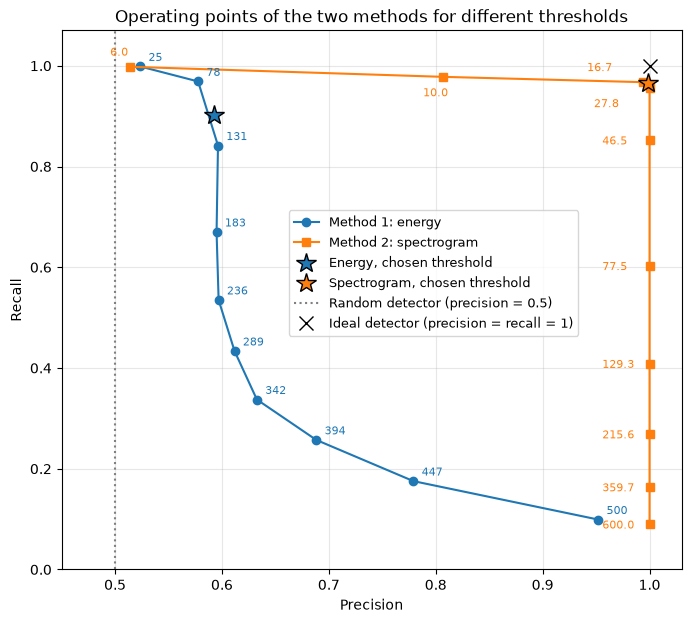

In [22]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(pr_energie[:, 0], pr_energie[:, 1], 'o-', label='Method 1: energy')
ax.plot(pr_spectro[:, 0], pr_spectro[:, 1], 's-', label='Method 2: spectrogram')

#value of the threshold next to each operating point
for s, (p, r) in zip(seuils_energie, pr_energie):
    ax.annotate(f'{s:.0f}', (p, r), textcoords='offset points', xytext=(6, 4), fontsize=8, color='C0')
for k, (s, (p, r)) in enumerate(zip(seuils_spectro, pr_spectro)):
    #the points near the top right corner are very close to each other: we alternate the labels above and below
    if r > 0.9:
        dx = -40 if p > 0.95 else -14
        offset = (dx, 8) if k % 2 == 0 else (dx, -14)
    else:
        offset = (-34, -3)
    ax.annotate(f'{s:.1f}', (p, r), textcoords='offset points', xytext=offset, fontsize=8, color='C1')

#operating points of the thresholds chosen in the previous sections
ax.plot(*precision_recall(energies, seuil_energie), '*', color='C0', markersize=15, markeredgecolor='k', label='Energy, chosen threshold')
ax.plot(*precision_recall(rapports, seuil_spectro), '*', color='C1', markersize=15, markeredgecolor='k', label='Spectrogram, chosen threshold')

#reference: a detector that answers at random has a precision equal to the proportion of signals with a pulse
ax.axvline(labels.mean(), color='gray', linestyle=':', label='Random detector (precision = 0.5)')
ax.plot(1, 1, 'kx', markersize=10, label='Ideal detector (precision = recall = 1)')

ax.set_xlim(0.45, 1.03)
ax.set_ylim(0, 1.07)
ax.set_xlabel('Precision')
ax.set_ylabel('Recall')
ax.set_title('Operating points of the two methods for different thresholds')
ax.legend(loc='center', bbox_to_anchor=(0.6, 0.55), fontsize=9)
ax.grid(alpha=0.3)
plt.show()

<div style="border-left: 4px solid #2e7d32; background-color: #f1f8f1; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#2e7d32;">Answer</b></p>

<p>The ideal detector is at (1, 1), and the spectrogram method is better for every threshold: for any recall, its precision is higher.</p>

<p><b>Energy.</b> The precision stays around 0.6, barely above a random detector (0.5), whatever the threshold: changing it mainly changes the recall. It only increases for the highest thresholds (0.95 at 500, since no signal without a pulse exceeds &asymp; 540), but then only 10 % of the pulses are detected.</p>

<p><b>Spectrogram.</b> The curve almost reaches the ideal corner. For thresholds between about 17 and 28, the precision is 0.99-1 and the recall 0.96-0.97, so the result is robust to the choice of the threshold. Higher thresholds only lose the weakest pulses, and below &asymp; 10 the threshold falls under the noise peaks and the precision drops.</p>

<p><b>Conclusion.</b> The energy depends on the unknown noise power, whereas the spectrogram method exploits the localisation of the pulse in time and frequency and normalises by the noise level, which gives an almost perfect detection.</p>
</div>

In [23]:
#the thresholds were chosen and evaluated on the same signals, which could make the results optimistic (overfitting).
#To check it, we split the signals at random into two halves: the threshold is chosen on the first half (train) and
#the accuracy is measured on the second one (test), which was not used to choose it. We repeat this 20 times
rng = np.random.default_rng(0)
for name, scores, seuil in [('Energy', energies, seuil_energie), ('Spectrogram', rapports, seuil_spectro)]:
    acc_test, thr = [], []
    for _ in range(20):
        perm = rng.permutation(len(labels))
        train, test = perm[:len(labels)//2], perm[len(labels)//2:]
        s = best_threshold(scores[train], labels[train])
        thr.append(s)
        acc_test.append(np.mean((scores[test] > s) == labels[test]))
    acc_all = np.mean((scores > seuil) == labels)
    print(f'{name:12s} accuracy: same data = {acc_all:.3f}, test half = {np.mean(acc_test):.3f} +- {np.std(acc_test):.3f}'
          f'   (threshold chosen on the train half = {np.mean(thr):.1f} +- {np.std(thr):.1f})')

Energy       accuracy: same data = 0.640, test half = 0.639 +- 0.005   (threshold chosen on the train half = 104.7 +- 5.7)
Spectrogram  accuracy: same data = 0.982, test half = 0.983 +- 0.002   (threshold chosen on the train half = 20.5 +- 0.6)


<div style="border-left: 4px solid #1565c0; background-color: #eef4fc; color: #1b1b1b; padding: 10px 16px; font-weight: normal;">
<p><b style="color:#1565c0;">Observation</b></p>

<p>Choosing the threshold on the same signals as those used for the evaluation does not bias the results: when it is chosen on one half of the signals and evaluated on the other, the accuracy is the same (63.9 % for the energy and 98.3 % for the spectrogram, against 64.0 % and 98.2 % on all the signals), and the chosen threshold barely changes from one split to another. This is expected, since each method only has one parameter, fitted on 5000 signals, so it cannot overfit the particular noise of these signals.</p>
</div>